# PJ1 - Deteksi dan Penghitungan Tanaman dari UAV

Notebook ini menyiapkan dataset Supervisely menjadi format YOLO, membagi data berdasarkan sesi penerbangan, memeriksa anotasi, menjalankan eksperimen E1/E2/E3, lalu mengevaluasi model terpilih pada test satu kali. Dirancang untuk dijalankan di Kaggle Notebook.

## Alur dan tujuan

Dataset yang digunakan adalah **Plant Detection and Counting**: citra UAV dengan anotasi bounding box untuk `maize`, `sugarbeet`, dan `sunflower`. Notebook ini menggabungkan alur program Python yang masih relevan: konversi anotasi Supervisely, pemeriksaan label, konversi YOLO/COCO dua arah, split data, lalu eksperimen YOLO E1/E2/E3. Setiap program diberi bagian Markdown tersendiri.

Program pengambil subset COCO tidak dipakai karena dataset UAV sudah tersedia. Program persiapan banana juga tidak dipakai pada alur ini. Data banana mentah tidak dihapus.

Di Kaggle, tambahkan dataset ini melalui **Add Input**, aktifkan accelerator GPU, dan aktifkan Internet jika bobot pretrained perlu diunduh. Jangan memasang ulang PyTorch; gunakan versi yang disediakan runtime Kaggle. Input Kaggle hanya dibaca, sedangkan data YOLO dan hasil training disimpan ke `/kaggle/working/plant_detection_project/`.

Lisensi dataset: CC BY 4.0. Sumber dan sitasi ada di bagian akhir notebook.

## Persiapan environment dan lokasi dataset

Tambahkan dataset UAV melalui Kaggle **Add Input**. Loader memeriksa path Kaggle yang diberikan dan juga mencari folder yang memiliki `meta.json`, `ds0/img/`, serta `ds0/ann/`. File input hanya dibaca; hasil olahan disimpan ke `/kaggle/working/plant_detection_project/`.

Pilih accelerator **GPU T4 x2** di pengaturan notebook. Training akan memakai kedua GPU jika tersedia; validation dan test berjalan pada GPU pertama. Jalankan ulang notebook dari awal setelah mengubah accelerator.

In [1]:
import importlib.metadata
import importlib.util
import subprocess
import sys
from pathlib import Path
import itertools
import json
import math
import random
import shutil
import time
from collections import Counter, defaultdict

import torch

required_packages = {
    "pandas": "pandas>=2.2",
    "matplotlib": "matplotlib",
    "PIL": "Pillow",
    "yaml": "PyYAML",
}
missing_packages = [
    package for module, package in required_packages.items()
    if importlib.util.find_spec(module) is None
]
if missing_packages:
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing_packages])

TARGET_ULTRALYTICS = "8.4.182"
try:
    current_ultralytics = importlib.metadata.version("ultralytics")
except importlib.metadata.PackageNotFoundError:
    current_ultralytics = None
if current_ultralytics != TARGET_ULTRALYTICS:
    subprocess.check_call([
        sys.executable,
        "-m",
        "pip",
        "install",
        "--no-deps",
        f"ultralytics=={TARGET_ULTRALYTICS}",
    ])

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import ultralytics
import yaml
from PIL import Image, ImageDraw

assert ultralytics.__version__ == TARGET_ULTRALYTICS, (
    f"Ultralytics {TARGET_ULTRALYTICS} diperlukan untuk YOLO26; ditemukan {ultralytics.__version__}"
)


def is_dataset_root(path):
    return (path / "meta.json").is_file() and (path / "ds0" / "img").is_dir() and (path / "ds0" / "ann").is_dir()


def find_dataset_root():
    direct_candidates = [
        Path("/kaggle/input/datasets/sangplanetdestroyer/dataset-uav-untuk-pj1-view-atas/datasets/plant-detection-and-counting-DatasetNinja"),
        Path("/kaggle/input/plant-detection-and-counting"),
        Path("/kaggle/input/plant-detection-and-counting-datasetninja"),
        Path.cwd() / "datasets" / "plant-detection-and-counting-DatasetNinja",
    ]
    for candidate in direct_candidates:
        if is_dataset_root(candidate):
            return candidate

    for search_root in (Path("/kaggle/input"), Path.cwd() / "datasets"):
        if not search_root.is_dir():
            continue
        for child in search_root.iterdir():
            if not child.is_dir():
                continue
            if is_dataset_root(child):
                return child
            for nested in child.iterdir():
                if nested.is_dir() and is_dataset_root(nested):
                    return nested
    raise FileNotFoundError(
        "Dataset belum ditemukan. Tambahkan dataset UAV lewat Kaggle Add Input."
    )


SOURCE_ROOT = find_dataset_root()
SOURCE_IMAGES = SOURCE_ROOT / "ds0" / "img"
SOURCE_ANNOTATIONS = SOURCE_ROOT / "ds0" / "ann"
METADATA = json.loads((SOURCE_ROOT / "meta.json").read_text(encoding="utf-8"))
CLASS_NAMES = [item["title"] for item in METADATA["classes"]]
CLASS_TO_ID = {name: index for index, name in enumerate(CLASS_NAMES)}
OUTPUT_ROOT = (
    Path("/kaggle/working/plant_detection_project")
    if Path("/kaggle/working").exists()
    else Path.cwd() / "plant_detection_project"
)
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

print("Dataset:", SOURCE_ROOT)
print("Kelas:", CLASS_TO_ID)
print("Output:", OUTPUT_ROOT)
print("PyTorch:", torch.__version__)
print("Ultralytics:", ultralytics.__version__)
print("CUDA tersedia:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 1.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 23.1 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Dataset: /kaggle/input/datasets/sangplanetdestroyer/dataset-uav-untuk-pj1-view-atas/datasets/plant-detection-and-counting-DatasetNinja
Kelas: {'maize': 0, 'sugarbeet': 1, 'sunflower': 2}
Output: /kaggle/working/plant_detection_project
PyTorch: 2.11.0+cu128
Ultralytics: 8.4.182
CUDA tersedia: True
GPU: Tesla T4


## Persiapan dataset: Supervisely ke YOLO

**Program konversi anotasi.** Dataset memakai JSON Supervisely, sedangkan Ultralytics membutuhkan satu file `.txt` YOLO per gambar. Sel ini mengubah kotak piksel menjadi koordinat YOLO ternormalisasi, menyalin gambar ke area kerja, dan menyimpan tag `site`, `year`, serta `flight_id` ke manifest untuk split per sesi penerbangan.

**Catatan audit tag dan kelas:** terdapat 4 gambar bertag `sugarbeet` yang anotasi objeknya berlabel `sunflower` (385 kotak). Notebook mempertahankan label objek dari anotasi dan tidak menggantinya otomatis berdasarkan tag gambar. Perbedaan ini perlu diperiksa saat membaca hasil; tag bisa menjelaskan plot, sedangkan kelas menjelaskan objek yang benar-benar diberi kotak.

In [2]:
YOLO_SOURCE = OUTPUT_ROOT / "yolo_source"
YOLO_SOURCE_IMAGES = YOLO_SOURCE / "images"
YOLO_SOURCE_LABELS = YOLO_SOURCE / "labels"
YOLO_SOURCE_IMAGES.mkdir(parents=True, exist_ok=True)
YOLO_SOURCE_LABELS.mkdir(parents=True, exist_ok=True)
(YOLO_SOURCE / "classes.txt").write_text("\n".join(CLASS_NAMES) + "\n", encoding="utf-8")

manifest_rows = []
class_counts = Counter()
clipped_boxes = 0

for annotation_path in sorted(SOURCE_ANNOTATIONS.glob("*.json")):
    image_name = annotation_path.name[:-5]  # buang akhiran .json, sisakan nama .png
    image_path = SOURCE_IMAGES / image_name
    if not image_path.is_file():
        raise FileNotFoundError(f"Gambar pasangan tidak ditemukan: {image_path}")

    annotation = json.loads(annotation_path.read_text(encoding="utf-8"))
    with Image.open(image_path) as image:
        image_width, image_height = image.size
    if annotation["size"]["width"] != image_width or annotation["size"]["height"] != image_height:
        raise ValueError(f"Ukuran anotasi dan gambar berbeda: {image_name}")

    tags = {tag["name"]: tag.get("value") for tag in annotation.get("tags", [])}
    group_key = "|".join(str(tags.get(key, "unknown")) for key in ("site", "year", "flight_id"))
    rows = []

    for obj in annotation.get("objects", []):
        class_name = obj.get("classTitle")
        if class_name not in CLASS_TO_ID:
            raise ValueError(f"Kelas tidak dikenal pada {image_name}: {class_name}")
        if obj.get("geometryType") != "rectangle":
            raise ValueError(f"Geometri bukan rectangle pada {image_name}")

        points = obj.get("points", {}).get("exterior", [])
        if len(points) != 2:
            raise ValueError(f"Bounding box harus memiliki dua titik pada {image_name}")
        (x1, y1), (x2, y2) = points
        left, right = sorted((float(x1), float(x2)))
        top, bottom = sorted((float(y1), float(y2)))
        clipped_left = min(max(left, 0.0), float(image_width))
        clipped_right = min(max(right, 0.0), float(image_width))
        clipped_top = min(max(top, 0.0), float(image_height))
        clipped_bottom = min(max(bottom, 0.0), float(image_height))
        clipped_boxes += int((left, right, top, bottom) != (clipped_left, clipped_right, clipped_top, clipped_bottom))
        if clipped_right <= clipped_left or clipped_bottom <= clipped_top:
            raise ValueError(f"Bounding box kosong setelah clipping pada {image_name}")

        center_x = ((clipped_left + clipped_right) / 2) / image_width
        center_y = ((clipped_top + clipped_bottom) / 2) / image_height
        box_width = (clipped_right - clipped_left) / image_width
        box_height = (clipped_bottom - clipped_top) / image_height
        class_id = CLASS_TO_ID[class_name]
        rows.append(f"{class_id} {center_x:.6f} {center_y:.6f} {box_width:.6f} {box_height:.6f}")
        class_counts[class_name] += 1

    shutil.copy2(image_path, YOLO_SOURCE_IMAGES / image_name)
    (YOLO_SOURCE_LABELS / f"{Path(image_name).stem}.txt").write_text(
        "\n".join(rows) + "\n", encoding="utf-8"
    )
    manifest_rows.append({
        "image": image_name,
        "group_key": group_key,
        "crop": str(tags.get("crop", "unknown")),
        "site": str(tags.get("site", "unknown")),
        "year": str(tags.get("year", "unknown")),
        "flight_id": str(tags.get("flight_id", "unknown")),
        "objects": len(rows),
    })

manifest = pd.DataFrame(manifest_rows).sort_values("image").reset_index(drop=True)
manifest.to_csv(OUTPUT_ROOT / "manifest.csv", index=False)
print(f"Gambar dan anotasi dikonversi: {len(manifest)}")
print(f"Jumlah bounding box: {sum(class_counts.values())} | per kelas: {dict(class_counts)}")
print(f"Kotak yang dipotong ke batas gambar: {clipped_boxes}")
print(f"Grup sesi penerbangan: {manifest['group_key'].nunique()}")
print("Manifest:", OUTPUT_ROOT / "manifest.csv")

Gambar dan anotasi dikonversi: 189
Jumlah bounding box: 16122 | per kelas: {'maize': 5257, 'sugarbeet': 5647, 'sunflower': 5218}
Kotak yang dipotong ke batas gambar: 0
Grup sesi penerbangan: 27
Manifest: /kaggle/working/plant_detection_project/manifest.csv


## Program 01 - Pemeriksaan anotasi YOLO

Bagian ini menggantikan pemeriksa `01_cek_anotasi.py`. Setiap file label harus berisi `class_id x_center y_center width height`, koordinat ternormalisasi 0–1, dan nama file yang cocok dengan gambar. Sampel visual dipakai untuk memastikan kotak benar-benar menutup tanaman.

Lolos: 189 gambar, 16122 kotak
Jumlah kotak per kelas: {'maize': 5257, 'sugarbeet': 5647, 'sunflower': 5218}


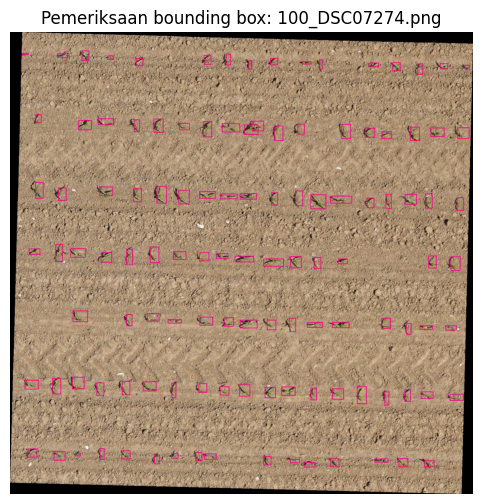

In [3]:
from PIL import ImageColor

image_files = sorted(YOLO_SOURCE_IMAGES.glob("*"))
label_files = {path.stem: path for path in YOLO_SOURCE_LABELS.glob("*.txt")}
assert len(image_files) == len(label_files), "Jumlah gambar dan label berbeda"
assert {path.stem for path in image_files} == set(label_files), "Nama pasangan gambar-label tidak cocok"

validated_counts = Counter()
for image_path in image_files:
    label_path = label_files[image_path.stem]
    with Image.open(image_path) as image:
        width, height = image.size
    for line_number, line in enumerate(label_path.read_text(encoding="utf-8").splitlines(), start=1):
        values = line.split()
        assert len(values) == 5, f"{label_path.name}:{line_number}: harus ada 5 kolom"
        class_id = int(values[0])
        coords = [float(value) for value in values[1:]]
        assert 0 <= class_id < len(CLASS_NAMES), f"Class id di luar daftar: {label_path.name}"
        assert all(math.isfinite(value) and 0 <= value <= 1 for value in coords), (
            f"Koordinat tidak valid: {label_path.name}:{line_number}"
        )
        assert coords[2] * width >= 1 and coords[3] * height >= 1, (
            f"Kotak terlalu kecil/kosong: {label_path.name}:{line_number}"
        )
        validated_counts[CLASS_NAMES[class_id]] += 1

print(f"Lolos: {len(image_files)} gambar, {sum(validated_counts.values())} kotak")
print("Jumlah kotak per kelas:", dict(validated_counts))

sample_path = image_files[0]
sample_label = label_files[sample_path.stem]
with Image.open(sample_path) as source_image:
    preview = source_image.convert("RGB")
    draw = ImageDraw.Draw(preview)
    for line in sample_label.read_text(encoding="utf-8").splitlines():
        class_id, center_x, center_y, box_width, box_height = line.split()
        center_x, center_y, box_width, box_height = map(float, (center_x, center_y, box_width, box_height))
        left = (center_x - box_width / 2) * preview.width
        top = (center_y - box_height / 2) * preview.height
        right = (center_x + box_width / 2) * preview.width
        bottom = (center_y + box_height / 2) * preview.height
        color = ["#F7018E", "#03C2B9", "#C9031B"][int(class_id)]
        draw.rectangle((left, top, right, bottom), outline=color, width=3)
    plt.figure(figsize=(16, 6))
    plt.imshow(preview)
    plt.title(f"Pemeriksaan bounding box: {sample_path.name}")
    plt.axis("off")
    plt.show()

## Program 02 - Konversi YOLO ke COCO

Bagian ini menggantikan `02_yolo_ke_coco.py`. Konversi ini opsional untuk training YOLO, tetapi dipakai di sini untuk memenuhi pemeriksaan format dua arah dan memastikan kelas serta posisi kotak tetap benar.

In [ ]:
coco_images = []
coco_annotations = []

for image_id, image_path in enumerate(image_files, start=1):
    with Image.open(image_path) as image:
        width, height = image.size
    coco_images.append({
        "id": image_id,
        "file_name": image_path.name,
        "width": width,
        "height": height,
    })
    label_path = label_files[image_path.stem]
    for line in label_path.read_text(encoding="utf-8").splitlines():
        class_id, center_x, center_y, box_width, box_height = line.split()
        class_id = int(class_id)
        center_x, center_y, box_width, box_height = map(
            float, (center_x, center_y, box_width, box_height)
        )
        pixel_width = box_width * width
        pixel_height = box_height * height
        left = center_x * width - pixel_width / 2
        top = center_y * height - pixel_height / 2
        coco_annotations.append({
            "id": len(coco_annotations) + 1,
            "image_id": image_id,
            "category_id": class_id + 1,
            "bbox": [left, top, pixel_width, pixel_height],
            "area": pixel_width * pixel_height,
            "iscrowd": 0,
        })

coco_data = {
    "images": coco_images,
    "annotations": coco_annotations,
    "categories": [
        {"id": index + 1, "name": name, "supercategory": "crop"}
        for index, name in enumerate(CLASS_NAMES)
    ],
}
COCO_JSON = OUTPUT_ROOT / "annotations_coco.json"
COCO_JSON.write_text(json.dumps(coco_data, indent=2), encoding="utf-8")
print(f"COCO tersimpan: {len(coco_images)} gambar, {len(coco_annotations)} anotasi -> {COCO_JSON}")

COCO tersimpan: 189 gambar, 16122 anotasi -> /kaggle/working/plant_detection_project/annotations_coco.json


## Program 03 - Konversi COCO kembali ke YOLO

Bagian ini menggantikan `03_coco_ke_yolo.py`. Label hasil konversi dibandingkan lagi dengan label awal. Jika jumlah gambar dan nilai kotaknya cocok, proses konversi dua arah lolos pemeriksaan.

In [ ]:
with COCO_JSON.open(encoding="utf-8") as file:
    coco_data = json.load(file)

categories = sorted(coco_data["categories"], key=lambda item: item["id"])
category_to_class = {item["id"]: index for index, item in enumerate(categories)}
image_annotations = defaultdict(list)
for item in coco_data["annotations"]:
    image_annotations[item["image_id"]].append(item)

ROUNDTRIP_LABELS = OUTPUT_ROOT / "roundtrip_labels"
ROUNDTRIP_LABELS.mkdir(parents=True, exist_ok=True)
(ROUNDTRIP_LABELS / "classes.txt").write_text("\n".join(CLASS_NAMES) + "\n", encoding="utf-8")

for image in coco_data["images"]:
    width, height = image["width"], image["height"]
    lines = []
    for item in image_annotations[image["id"]]:
        left, top, box_width, box_height = item["bbox"]
        center_x = (left + box_width / 2) / width
        center_y = (top + box_height / 2) / height
        class_id = category_to_class[item["category_id"]]
        lines.append(
            f"{class_id} {center_x:.6f} {center_y:.6f} "
            f"{box_width / width:.6f} {box_height / height:.6f}"
        )
    (ROUNDTRIP_LABELS / f"{Path(image['file_name']).stem}.txt").write_text(
        "\n".join(lines) + ("\n" if lines else ""), encoding="utf-8"
    )

max_roundtrip_error = 0.0
for label_path in YOLO_SOURCE_LABELS.glob("*.txt"):
    original = label_path.read_text(encoding="utf-8").splitlines()
    converted = (ROUNDTRIP_LABELS / label_path.name).read_text(encoding="utf-8").splitlines()
    assert len(original) == len(converted), f"Jumlah kotak berubah: {label_path.name}"
    for original_line, converted_line in zip(original, converted):
        original_values = [float(value) for value in original_line.split()]
        converted_values = [float(value) for value in converted_line.split()]
        assert int(original_values[0]) == int(converted_values[0])
        max_roundtrip_error = max(
            max_roundtrip_error,
            *(abs(a - b) for a, b in zip(original_values[1:], converted_values[1:])),
        )
assert max_roundtrip_error < 1e-5, f"Selisih round-trip terlalu besar: {max_roundtrip_error}"
print(f"PASS: round-trip COCO/YOLO, selisih koordinat maksimum {max_roundtrip_error:.2e}")

PASS: round-trip COCO/YOLO, selisih koordinat maksimum 0.00e+00


## Program 05 - Split train/validation/test per sesi penerbangan

Dataset tidak menyediakan split resmi. Program `05_split_dataset_yolo.py` lama membagi gambar secara acak, tetapi untuk citra UAV itu berisiko menaruh gambar dari sesi yang sama di train dan test. Bagian ini memakai grup `site + year + flight_id`, menjaga semua kelas tetap ada di setiap split, lalu mencari pembagian grup yang paling mendekati 70/15/15.

In [6]:
group_info = manifest.groupby("group_key").agg(crop=("crop", "first"), images=("image", "count"))
assert manifest.groupby("group_key")["crop"].nunique().max() == 1, "Satu flight memuat label crop berbeda"
groups_by_crop = {
    crop: group_info.index[group_info["crop"] == crop].tolist()
    for crop in CLASS_NAMES
}
assert all(len(groups_by_crop[crop]) >= 3 for crop in CLASS_NAMES), (
    "Setiap kelas perlu minimal tiga flight untuk split train/val/test"
)

# Pilih satu flight val dan satu flight test per kelas; sisanya masuk train.
random_generator = random.Random(42)
options_by_crop = []
for crop in CLASS_NAMES:
    crop_groups = groups_by_crop[crop].copy()
    random_generator.shuffle(crop_groups)
    options_by_crop.append(list(itertools.permutations(crop_groups, 2)))

all_groups = set(group_info.index)
group_sizes = group_info["images"].astype(int).to_dict()
total_images = sum(group_sizes.values())
target_fractions = {"train": 0.70, "val": 0.15, "test": 0.15}
best_score = float("inf")
best_split_groups = None

for choices in itertools.product(*options_by_crop):
    val_groups = {choice[0] for choice in choices}
    test_groups = {choice[1] for choice in choices}
    train_groups = all_groups - val_groups - test_groups
    val_images = sum(group_sizes[group] for group in val_groups)
    test_images = sum(group_sizes[group] for group in test_groups)
    image_counts = {
        "train": total_images - val_images - test_images,
        "val": val_images,
        "test": test_images,
    }
    score = sum(
        (image_counts[split] / total_images - target_fractions[split]) ** 2
        for split in target_fractions
    )
    if score < best_score:
        best_score = score
        best_split_groups = {
            "train": train_groups,
            "val": val_groups,
            "test": test_groups,
        }

assert best_split_groups is not None
assert not (best_split_groups["train"] & best_split_groups["val"])
assert not (best_split_groups["train"] & best_split_groups["test"])
assert not (best_split_groups["val"] & best_split_groups["test"])

split_by_group = {
    group: split
    for split, groups in best_split_groups.items()
    for group in groups
}
manifest["split"] = manifest["group_key"].map(split_by_group)
assert manifest["split"].notna().all()

YOLO_DATASET = OUTPUT_ROOT / "dataset_v1"
for split in ("train", "val", "test"):
    (YOLO_DATASET / "images" / split).mkdir(parents=True, exist_ok=True)
    (YOLO_DATASET / "labels" / split).mkdir(parents=True, exist_ok=True)
    for row in manifest.loc[manifest["split"] == split].itertuples(index=False):
        shutil.copy2(YOLO_SOURCE_IMAGES / row.image, YOLO_DATASET / "images" / split / row.image)
        shutil.copy2(
            YOLO_SOURCE_LABELS / f"{Path(row.image).stem}.txt",
            YOLO_DATASET / "labels" / split / f"{Path(row.image).stem}.txt",
        )

DATA_YAML = YOLO_DATASET / "data.yaml"
DATA_YAML.write_text(
    yaml.safe_dump(
        {
            "path": str(YOLO_DATASET.resolve()),
            "train": "images/train",
            "val": "images/val",
            "test": "images/test",
            "names": CLASS_NAMES,
        },
        sort_keys=False,
    ),
    encoding="utf-8",
)
manifest.to_csv(OUTPUT_ROOT / "manifest_with_split.csv", index=False)

split_summary = manifest.groupby("split").agg(images=("image", "count"), objects=("objects", "sum"))
print(split_summary)
print("Proporsi gambar:", (split_summary["images"] / total_images).round(3).to_dict())
print("Grup flight per split:", {name: len(groups) for name, groups in best_split_groups.items()})
print("data.yaml:", DATA_YAML)

       images  objects
split                 
test       28     1898
train     134    12467
val        27     1757
Proporsi gambar: {'test': 0.148, 'train': 0.709, 'val': 0.143}
Grup flight per split: {'train': 21, 'val': 3, 'test': 3}
data.yaml: /kaggle/working/plant_detection_project/dataset_v1/data.yaml


### Pemeriksaan kelas pada setiap split

Ringkasan ini menghitung jumlah bounding box maize, sugarbeet, dan sunflower di train, validation, serta test. Pastikan setiap kelas muncul di ketiga bagian sebelum training dimulai.

In [7]:
split_class_counts = (
    manifest.groupby(["split", "crop"])["objects"]
    .sum()
    .unstack(fill_value=0)
    .reindex(columns=CLASS_NAMES, fill_value=0)
)
display(split_class_counts)

crop,maize,sugarbeet,sunflower
split,,,
test,594,647,657
train,4153,4716,3598
val,510,669,578


## Program 06 - Training E1, E2, dan E3

Bagian ini menggabungkan fungsi utama `06_latih_bandingkan.py`. Ketiga eksperimen memakai split, seed, epoch, dan batch yang sama. E1 memakai bobot pretrained COCO; E2 mulai dari bobot acak; E3 mengubah satu hal saja, yaitu ukuran input dari 640 ke 896. Training memakai dua GPU jika Kaggle menyediakan T4 x2; validation dan test memakai GPU pertama. Sel training berhenti dengan pesan jika GPU tidak terdeteksi. Mengulang sel ini akan melatih ulang ketiga model.

In [8]:
from ultralytics import YOLO

NIM = "4222401015"
NAMA = "Abdul-Hamid"
EPOCHS = 30
BASE_IMGSZ = 640
TUNED_IMGSZ = 896
BATCH_SIZE = 8
GPU_COUNT = torch.cuda.device_count()
if GPU_COUNT == 0:
    raise RuntimeError(
        "GPU tidak terdeteksi. Di Kaggle, pilih Settings > Accelerator > GPU, restart session, lalu jalankan ulang notebook."
    )
TRAIN_DEVICE = [0, 1] if GPU_COUNT >= 2 else 0
EVAL_DEVICE = 0
GPU_NAMES = [torch.cuda.get_device_name(index) for index in range(min(GPU_COUNT, 2))]
RUNS_DIR = OUTPUT_ROOT / "runs"
RUNS_DIR.mkdir(parents=True, exist_ok=True)

pretrained_candidates = []
for search_root in (Path("/kaggle/input"), Path.cwd()):
    if search_root.exists():
        pretrained_candidates.extend(search_root.rglob("yolo26n.pt"))
PRETRAINED_MODEL = str(pretrained_candidates[0]) if pretrained_candidates else "yolo26n.pt"

print("Training device(s):", TRAIN_DEVICE)
print("GPU(s):", GPU_NAMES)
print("Validation/test device:", EVAL_DEVICE)
print("Pretrained checkpoint:", PRETRAINED_MODEL)


def run_experiment(name, model_source, pretrained, image_size):
    model = YOLO(model_source)
    start_time = time.time()
    model.train(
        data=str(DATA_YAML),
        epochs=EPOCHS,
        imgsz=image_size,
        batch=BATCH_SIZE,
        device=TRAIN_DEVICE,
        workers=2,
        seed=42,
        deterministic=True,
        pretrained=pretrained,
        project=str(RUNS_DIR),
        name=name,
        exist_ok=True,
        plots=True,
        verbose=True,
        close_mosaic=10,
    )
    elapsed_minutes = (time.time() - start_time) / 60
    save_dir = Path(model.trainer.save_dir)
    best_weights = save_dir / "weights" / "best.pt"
    metrics = YOLO(str(best_weights)).val(
        data=str(DATA_YAML),
        split="val",
        imgsz=image_size,
        batch=BATCH_SIZE,
        device=EVAL_DEVICE,
        plots=False,
        verbose=False,
    )
    return {
        "experiment": name,
        "change": "-" if name != "E3_tuning" else f"imgsz={image_size}",
        "pretrained": pretrained,
        "imgsz": image_size,
        "mAP50": round(float(metrics.box.map50), 4),
        "mAP50-95": round(float(metrics.box.map), 4),
        "precision": round(float(metrics.box.mp), 4),
        "recall": round(float(metrics.box.mr), 4),
        "inference_ms": round(float(metrics.speed["inference"]), 2),
        "train_minutes": round(elapsed_minutes, 2),
        "best_weights": str(best_weights),
    }


experiment_results = [
    run_experiment("E1_pretrained", PRETRAINED_MODEL, True, BASE_IMGSZ),
    run_experiment("E2_scratch", "yolo26n.yaml", False, BASE_IMGSZ),
    run_experiment("E3_tuning", PRETRAINED_MODEL, True, TUNED_IMGSZ),
]
results_table = pd.DataFrame(experiment_results)
display(results_table)
RESULTS_CSV = OUTPUT_ROOT / f"hasil_praktik_{NIM}.csv"
results_table.to_csv(RESULTS_CSV, index=False)
print("CSV:", RESULTS_CSV)

Training device(s): [0, 1]
GPU(s): ['Tesla T4', 'Tesla T4']
Validation/test device: 0
Pretrained checkpoint: yolo26n.pt
Ultralytics 8.4.182 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
                                                        CUDA:1 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/plant_detection_project/dataset_v1/data.yaml, degrees=0.0, deterministic=True, device=0,1, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(



      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
       2/30      1.45G      2.937      4.178   0.003819        394        640: 100% ━━━━━━━━━━━━ 17/17 3.6it/s 4.7s0.3s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 4.7it/s 0.4s0.6s
                   all         27       1757      0.926      0.231      0.272      0.107

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
       3/30      1.56G       2.79      3.366   0.003116        529        640: 100% ━━━━━━━━━━━━ 17/17 3.8it/s 4.5s0.3s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 6.1it/s 0.3s0.4s
                   all         27       1757      0.353      0.551      0.429      0.132

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
       4/30      1.56G      2.678      2.747   0.003222        422        640: 100% ━━━

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(



      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
       2/30      1.44G      4.921      4.373     0.0152        394        640: 100% ━━━━━━━━━━━━ 17/17 3.7it/s 4.6s0.3s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 7.9it/s 0.3s
                   all         27       1757          0          0          0          0

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
       3/30      1.54G      4.945      4.205    0.01393        529        640: 100% ━━━━━━━━━━━━ 17/17 3.7it/s 4.6s0.3s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 8.8it/s 0.2s
                   all         27       1757          0          0          0          0

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
       4/30      1.54G      4.405      3.971    0.01157        422        640: 100% ━━━━━━━━━━━

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(



      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
       2/30       2.5G      2.529      4.211   0.002894        394        896: 100% ━━━━━━━━━━━━ 17/17 3.3it/s 5.2s0.3s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 3.5it/s 0.6s0.9s
                   all         27       1757      0.754      0.578       0.58      0.284

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
       3/30      2.92G      2.352      3.416   0.002395        535        896: 100% ━━━━━━━━━━━━ 17/17 3.2it/s 5.3s0.3s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 3.9it/s 0.5s0.9s
                   all         27       1757      0.474      0.711      0.628       0.29

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
       4/30      2.92G      2.261       2.77   0.002464        423        896: 100% ━━━

,experiment,change,pretrained,imgsz,mAP50,mAP50-95,precision,recall,inference_ms,train_minutes,best_weights
0,E1_pretrained,-,True,640,0.7060,0.3751,0.7475,0.7137,9.96,4.36,/kaggle/working/plant_detection_project/runs/E...
1,E2_scratch,-,False,640,0.3283,0.1353,0.3541,0.4036,3.57,3.94,/kaggle/working/plant_detection_project/runs/E...
2,E3_tuning,imgsz=896,True,896,0.7471,0.4112,0.8058,0.7577,11.18,4.34,/kaggle/working/plant_detection_project/runs/E...


CSV: /kaggle/working/plant_detection_project/hasil_praktik_4222401015.csv


## Pilih model dari validation dan uji test satu kali

Model dipilih dari nilai mAP50-95 validation tertinggi. Hanya model terpilih yang dijalankan pada test, tepat satu kali, agar test tidak dipakai untuk tuning. Hasil, grafik, dan bobot tersimpan di `/kaggle/working/plant_detection_project/` dan dapat diunduh dari bagian Output Kaggle.

In [9]:
best_row = results_table.sort_values("mAP50-95", ascending=False).iloc[0]
best_model_path = best_row["best_weights"]
print(f"Model terpilih dari validation: {best_row['experiment']} (mAP50-95={best_row['mAP50-95']:.4f})")

# Jalankan sel ini satu kali setelah model terpilih; jangan gunakan test untuk tuning.
test_model = YOLO(best_model_path)
test_metrics = test_model.val(
    data=str(DATA_YAML),
    split="test",
    imgsz=int(best_row["imgsz"]),
    batch=BATCH_SIZE,
    device=EVAL_DEVICE,
    plots=True,
    verbose=True,
)
test_result = {
    "selected_model": best_row["experiment"],
    "test_mAP50": round(float(test_metrics.box.map50), 4),
    "test_mAP50-95": round(float(test_metrics.box.map), 4),
    "test_precision": round(float(test_metrics.box.mp), 4),
    "test_recall": round(float(test_metrics.box.mr), 4),
    "test_inference_ms": round(float(test_metrics.speed["inference"]), 2),
}
print(test_result)

from datetime import datetime
report_lines = [
    "PJ1 - PLANT DETECTION AND COUNTING",
    f"NIM / Nama: {NIM} / {NAMA}",
    f"Waktu: {datetime.now():%Y-%m-%d %H:%M:%S}",
    f"Dataset: {SOURCE_ROOT}",
    f"Training device(s): {TRAIN_DEVICE} ({', '.join(GPU_NAMES)})",
    f"Validation/test device: GPU {EVAL_DEVICE}",
    f"Split: group by site/year/flight_id; seed=42",
    f"Training: yolo26n, epochs={EPOCHS}, imgsz={BASE_IMGSZ}, batch={BATCH_SIZE}; E3 imgsz={TUNED_IMGSZ}",
    "",
    results_table.to_string(index=False),
    "",
    f"Selected by validation mAP50-95: {test_result['selected_model']}",
    f"TEST (evaluated once): mAP50={test_result['test_mAP50']}, mAP50-95={test_result['test_mAP50-95']}, precision={test_result['test_precision']}, recall={test_result['test_recall']}",
]
REPORT_TXT = OUTPUT_ROOT / f"hasil_praktik_{NIM}.txt"
REPORT_TXT.write_text("\n".join(report_lines) + "\n", encoding="utf-8")
print("TXT:", REPORT_TXT)
print("E1 graph:", RUNS_DIR / "E1_pretrained" / "results.png")
print("E3 graph:", RUNS_DIR / "E3_tuning" / "results.png")

Model terpilih dari validation: E3_tuning (mAP50-95=0.4112)
Ultralytics 8.4.182 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO26n summary (fused): 121 layers, 2,390,221 parameters, 0 gradients
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3895.2±1432.5 MB/s, size: 3831.7 KB)
val: Scanning /kaggle/working/plant_detection_project/dataset_v1/labels/test... 28 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 28/28 43.4it/s 0.6s0.1s
val: New cache created: /kaggle/working/plant_detection_project/dataset_v1/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 1.4s/it 5.4s2.0s
                   all         28       1898      0.915      0.922      0.948      0.514
                 maize          8        594      0.882      0.827      0.873       0.33
             sugarbeet          8        647      0.904      0.986      0.991      0.566
             sunflower         12        657      

## Cara membaca hasil dan batas pemakaian

- Bandingkan E1 dengan E2 untuk melihat pengaruh pretrained COCO. Bandingkan E1 dengan E3 untuk melihat pengaruh ukuran input.
- Model dipilih berdasarkan mAP50-95 validation. Test hanya dijalankan sekali untuk model terpilih.
- Dataset ini cocok untuk deteksi dan penghitungan tiga jenis tanaman pada citra UAV. Dataset ini **tidak** memiliki label kondisi tanaman atau `semprot/tidak semprot`, sehingga hasilnya tidak membuktikan kemampuan keputusan sprayer.
- Split dibuat berdasarkan `site/year/flight_id`, bukan acak per gambar, agar satu sesi penerbangan tidak tersebar ke train dan test.
- Hasil eksperimen, grafik, dan bobot dapat diunduh dari `/kaggle/working/plant_detection_project/` setelah notebook selesai.

**Sumber dataset:** David, E. (2021). *Plant detection and counting from high-resolution RGB images acquired from UAVs*. Zenodo, DOI [10.1101/2021.04.27.441631](https://doi.org/10.1101/2021.04.27.441631). Lisensi CC BY 4.0. Sertakan atribusi ini saat menggunakan atau membagikan hasil.

In [10]:
import os
import zipfile

source = "/kaggle/working"
output = "/kaggle/working/hasil_kaggle.zip"

with zipfile.ZipFile(output, "w", zipfile.ZIP_DEFLATED) as zipf:
    for root, dirs, files in os.walk(source):
        for file in files:
            filepath = os.path.join(root, file)

            if filepath == output:
                continue

            arcname = os.path.relpath(filepath, source)
            zipf.write(filepath, arcname)

print(f"Arsip berhasil dibuat: {output}")
print(f"Ukuran: {os.path.getsize(output) / (1024**2):.2f} MB")

Arsip berhasil dibuat: /kaggle/working/hasil_kaggle.zip
Ukuran: 1694.17 MB
